<a href="https://colab.research.google.com/github/AhmadFebriyan5/Studi-Kasus_Machine-Learning/blob/main/1_Make_Sense_of_Data_with_Analysis_and_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prediksi Keterlambatan Pembayaran Invoice
**Studi kasus simulasi PT Maju Bersama**  
Target: `late_payment_flag` (1 = terlambat >30 hari, 0 = tidak).  
*Data yang digunakan adalah data sintetis untuk demonstrasi.*

## 1. Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score

np.random.seed(42)

## 2. Membuat Dataset Simulasi

In [2]:
n = 1200

df = pd.DataFrame({
    "invoice_amount": np.random.lognormal(15, 0.65, n).round(0),
    "previous_delay_days": np.clip(np.random.gamma(2, 7, n), 0, 90).round(0),
    "open_invoice_count": np.random.poisson(2, n),
    "customer_tenure_months": np.random.randint(1, 121, n),
    "payment_terms_days": np.random.choice([14, 30, 45, 60], n),
    "payment_method": np.random.choice(["Transfer", "Kartu", "Cek"], n),
    "customer_segment": np.random.choice(["Retail", "UMKM", "Enterprise"], n)
})

logit = (-2.2 + 0.045 * df["previous_delay_days"]
         + 0.28 * df["open_invoice_count"]
         + 0.0000015 * df["invoice_amount"]
         - 0.012 * df["customer_tenure_months"]
         + np.where(df["payment_method"] == "Cek", 0.55, 0)
         + np.where(df["customer_segment"] == "Enterprise", 0.25, 0))

prob = 1 / (1 + np.exp(-logit))
df["late_payment_flag"] = np.random.binomial(1, prob)

display(df.head())
print("Ukuran dataset:", df.shape)
print(df["late_payment_flag"].value_counts())

,invoice_amount,previous_delay_days,open_invoice_count,customer_tenure_months,payment_terms_days,payment_method,customer_segment,late_payment_flag
0,4514767.0,13.0,0,4,14,Transfer,Retail,1
1,2988040.0,8.0,4,118,14,Cek,UMKM,1
2,4980284.0,12.0,4,38,30,Transfer,Retail,1
3,8797423.0,12.0,1,117,30,Kartu,UMKM,1
4,2807487.0,3.0,3,63,60,Transfer,Enterprise,1


Ukuran dataset: (1200, 8)
late_payment_flag
1    1079
0     121
Name: count, dtype: int64


## 3. Pemeriksaan Data

Missing values:
invoice_amount            0
previous_delay_days       0
open_invoice_count        0
customer_tenure_months    0
payment_terms_days        0
payment_method            0
customer_segment          0
late_payment_flag         0
dtype: int64

Duplikasi: 0


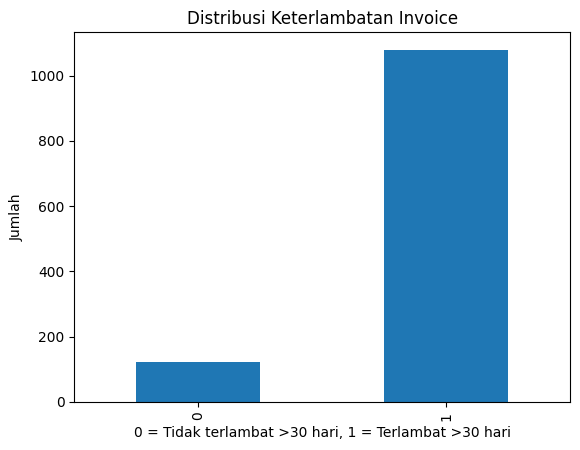

In [3]:
print("Missing values:")
print(df.isna().sum())
print("\nDuplikasi:", df.duplicated().sum())

df["late_payment_flag"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribusi Keterlambatan Invoice")
plt.xlabel("0 = Tidak terlambat >30 hari, 1 = Terlambat >30 hari")
plt.ylabel("Jumlah")
plt.show()

## 4. Preprocessing dan Pembagian Data

In [4]:
X = df.drop(columns="late_payment_flag")
y = df["late_payment_flag"]

num_cols = [
    "invoice_amount", "previous_delay_days", "open_invoice_count",
    "customer_tenure_months", "payment_terms_days"
]
cat_cols = ["payment_method", "customer_segment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

## 5. Training Model

In [5]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42
    ))
])

model.fit(X_train, y_train)
print("Training selesai.")

Training selesai.


## 6. Evaluasi Model

              precision    recall  f1-score   support

           0       0.32      0.83      0.46        30
           1       0.98      0.80      0.88       270

    accuracy                           0.80       300
   macro avg       0.65      0.82      0.67       300
weighted avg       0.91      0.80      0.84       300

ROC-AUC: 0.885


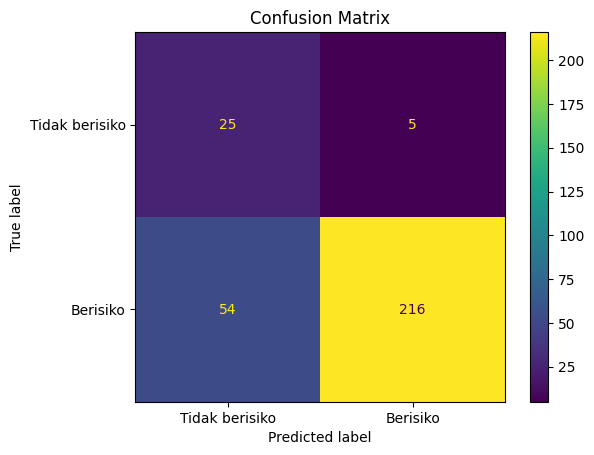

In [6]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Tidak berisiko", "Berisiko"]
)
plt.title("Confusion Matrix")
plt.show()

## 7. Prediksi dan Prioritas Invoice

In [7]:
hasil = X_test.copy()
hasil["aktual"] = y_test
hasil["prediksi"] = y_pred
hasil["probabilitas_risiko"] = y_prob
hasil["rekomendasi"] = np.where(
    hasil["probabilitas_risiko"] >= 0.50,
    "Prioritas tindak lanjut", "Pemantauan rutin"
)

display(hasil.sort_values("probabilitas_risiko", ascending=False).head(10))

,invoice_amount,previous_delay_days,open_invoice_count,customer_tenure_months,payment_terms_days,payment_method,customer_segment,aktual,prediksi,probabilitas_risiko,rekomendasi
478,24185710.0,26.0,2,22,14,Kartu,Enterprise,1,1,1.0,Prioritas tindak lanjut
762,17262636.0,11.0,1,35,14,Cek,UMKM,1,1,1.0,Prioritas tindak lanjut
880,16894625.0,5.0,1,55,30,Transfer,Enterprise,1,1,1.0,Prioritas tindak lanjut
220,14717209.0,42.0,3,55,14,Transfer,UMKM,1,1,1.0,Prioritas tindak lanjut
583,14302578.0,2.0,1,59,30,Kartu,Enterprise,1,1,1.0,Prioritas tindak lanjut
909,13337839.0,17.0,2,69,14,Cek,Retail,1,1,1.0,Prioritas tindak lanjut
125,13575757.0,5.0,2,52,60,Cek,Retail,1,1,1.0,Prioritas tindak lanjut
1023,13157148.0,14.0,1,109,60,Transfer,Retail,1,1,1.0,Prioritas tindak lanjut
885,10857425.0,37.0,1,63,45,Cek,Retail,1,1,1.0,Prioritas tindak lanjut
1024,10048190.0,33.0,0,6,30,Cek,Enterprise,1,1,1.0,Prioritas tindak lanjut


## 8. Prediksi Invoice Baru

In [8]:
invoice_baru = pd.DataFrame([{
    "invoice_amount": 25_000_000,
    "previous_delay_days": 35,
    "open_invoice_count": 4,
    "customer_tenure_months": 18,
    "payment_terms_days": 30,
    "payment_method": "Cek",
    "customer_segment": "UMKM"
}])

risiko = model.predict_proba(invoice_baru)[0, 1]
print(f"Probabilitas risiko: {risiko:.1%}")
print("Prioritas tindak lanjut" if risiko >= 0.50 else "Pemantauan rutin")

Probabilitas risiko: 100.0%
Prioritas tindak lanjut
